# 05 · Análisis histórico (R4)
Parte del DW que deja `03_dw` (`data/dw/covid_dw.zip`). Responde las preguntas del Comité con
**número + gráfico + interpretación**, usando casos y fallecidos **nuevos** (nunca acumulados como si fueran diarios),
**media móvil de 7 días** y **tasas por 100.000 habitantes**.

| Historia | Sección |
|---|---|
| H5.1 · Funciones comunes | 1 |
| H5.2 · P1 Chile frente a Sudamérica y sus olas | 2 |
| H5.3 · P2 Regiones de Chile, Biobío y mapa regional | 3 |
| H5.4 · P3 Letalidad aparente y vacunación | 4 |
| H5.5 · P4 Confiabilidad de los datos por país | 5 |
| H5.8 · P7 Vacunación temprana y fallecidos en ómicron | 6 |

**P5 (H5.6) y P6 (H5.7) están en `06_mineria.ipynb`** (secciones 5 y 6), porque usan la segmentación, `pronosticar` y `alerta` de ese notebook.

In [1]:
import sqlite3
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

# El DW se sube comprimido (pesa ~130 MB): primero se descomprime
zipfile.ZipFile("../data/dw/covid_dw.zip").extractall("../data/dw")
dw = sqlite3.connect("../data/dw/covid_dw.db")

## 1 · Funciones comunes (H5.1)
Tres funciones que usan todas las preguntas:

- `serie_pais(pais)`: casos y fallecidos nuevos de un país, día a día. Usa la **opción C** (igual que en H2.1 y H3.4):
  primero suma los **acumulados** de todos los territorios del país y después resta el día anterior.
  Así no se pierden los casos del día en que Chile pasó de nacional a regional (sumar `casos_nuevos` deja fuera 4.038).
  El primer día, los nuevos son el acumulado completo (antes no había casos).
  Los días en que el acumulado baja quedan **negativos**: se marcan, no se borran (decisión de H2.4); la media móvil los suaviza.
- `media_movil_7(serie)`: promedio de los últimos 7 días (incluido el día). Quita el efecto del fin de semana y de los
  informes semanales de 2022.
- `tasa_100k(valor, poblacion)`: valor por cada 100.000 habitantes, para comparar países de distinto tamaño.
  La población es `poblacion_pais` de `dim_territorio` (viene de la tabla UID).

In [2]:
SERIE_PAIS = """
    SELECT d.fecha,
           SUM(f.casos_acumulados)      AS casos_acumulados,
           SUM(f.fallecidos_acumulados) AS fallecidos_acumulados,
           MAX(t.poblacion_pais)        AS poblacion
    FROM fact_covid f
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    WHERE t.pais = ?
    GROUP BY d.fecha
    ORDER BY d.fecha
"""


def serie_pais(pais):
    """Casos y fallecidos nuevos de un país por día (opción C: sumar acumulados y después restar el día anterior)."""
    serie = pd.read_sql(SERIE_PAIS, dw, params=[pais], parse_dates=["fecha"])
    for medida in ["casos", "fallecidos"]:
        acumulado = serie[f"{medida}_acumulados"]
        serie[f"{medida}_nuevos"] = acumulado.diff().fillna(acumulado)  # el primer día: todo el acumulado
    return serie


def media_movil_7(serie):
    """Promedio de los últimos 7 días (incluido el día)."""
    return serie.rolling(7).mean()


def tasa_100k(valor, poblacion):
    """Valor por cada 100.000 habitantes."""
    return valor / poblacion * 100_000

### Prueba con Chile
Control: la suma de los casos nuevos tiene que dar el último acumulado (5.192.286 casos y 64.273 fallecidos, H2.1).

In [3]:
chile = serie_pais("Chile")
ultimo = chile.iloc[-1]

control = pd.DataFrame({
    "medida": ["casos", "fallecidos"],
    "suma de nuevos": [chile["casos_nuevos"].sum(), chile["fallecidos_nuevos"].sum()],
    "acumulado al 9-mar-2023": [ultimo["casos_acumulados"], ultimo["fallecidos_acumulados"]],
    "días con nuevos < 0": [(chile["casos_nuevos"] < 0).sum(), (chile["fallecidos_nuevos"] < 0).sum()],
})
control["cuadra"] = (control["suma de nuevos"] == control["acumulado al 9-mar-2023"]).map({True: "OK", False: "REVISAR"})
print("Días:", len(chile), "·", chile["fecha"].min().date(), "→", chile["fecha"].max().date())
control

Días: 1102 · 2020-03-03 → 2023-03-09


,medida,suma de nuevos,acumulado al 9-mar-2023,días con nuevos < 0,cuadra
0,casos,5192286.0,5192286.0,1,OK
1,fallecidos,64273.0,64273.0,2,OK


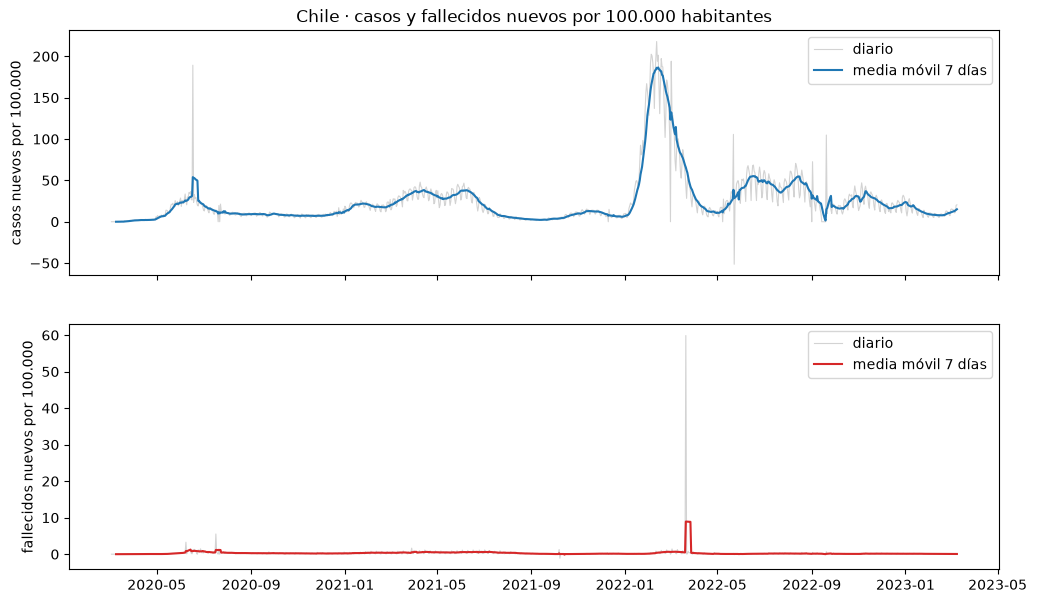

In [4]:
# Casos y fallecidos nuevos por 100.000: el dato diario (gris) y la media móvil de 7 días (color)
fig, ejes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for eje, medida, color in zip(ejes, ["casos", "fallecidos"], ["tab:blue", "tab:red"]):
    diario = tasa_100k(chile[f"{medida}_nuevos"], chile["poblacion"])
    eje.plot(chile["fecha"], diario, color="lightgray", linewidth=0.8, label="diario")
    eje.plot(chile["fecha"], media_movil_7(diario), color=color, label="media móvil 7 días")
    eje.set_ylabel(f"{medida} nuevos por 100.000")
    eje.legend()
ejes[0].set_title("Chile · casos y fallecidos nuevos por 100.000 habitantes")
plt.show()

**Lo que se ve (verificado):**
- Las funciones cuadran: la suma de nuevos da el acumulado final de casos y de fallecidos (control OK).
- El peor momento en casos es ómicron: media móvil de **186,5 casos por 100.000** el 13-feb-2022.
- **Ojo con los fallecidos:** el 21-mar-2022 el acumulado de Chile sube **11.447 fallecidos en un solo día** (≈ 60 por 100.000).
  Es una carga en bloque, no muertes de ese día, y no quedó marcada como `pico_rezago`. Durante 7 días eleva la media
  móvil a ≈ 8,9 por 100.000. Hay que tenerlo en cuenta al elegir la "peor ola" por fallecidos (P1).
- Días con nuevos negativos (acumulado que baja): 1 en casos (23-may-2022, −9.827) y 2 en fallecidos (8-oct-2021 y 23-may-2022).

## 2 · P1: ¿Cómo vivió Chile la pandemia frente a Sudamérica? (H5.2)
**Sudamérica** = los 10 países hispanos y lusos del continente: Argentina, Bolivia, Brasil, Chile, Colombia, Ecuador,
Paraguay, Perú, Uruguay y Venezuela (Guyana y Surinam quedan fuera). "Sudamérica" como total = suma de los 10
países, dividida por la suma de sus poblaciones.

In [5]:
SUDAMERICA = ["Argentina", "Bolivia", "Brazil", "Chile", "Colombia",
              "Ecuador", "Paraguay", "Peru", "Uruguay", "Venezuela"]

series = []
for pais in SUDAMERICA:
    serie = serie_pais(pais)
    serie["pais"] = pais
    series.append(serie)
sudamerica = pd.concat(series, ignore_index=True)

# Total de la región: sumar los nuevos de los 10 países por día
poblacion_region = sudamerica.groupby("pais")["poblacion"].max().sum()
region = sudamerica.groupby("fecha")[["casos_nuevos", "fallecidos_nuevos"]].sum().reset_index()
region["poblacion"] = poblacion_region
print("Población de la región:", f"{poblacion_region:,.0f}")

Población de la región: 429,084,414


### Totales por 100.000 al 9-mar-2023
Último acumulado de cada país dividido por su población.

In [6]:
ultimo_dia = sudamerica[sudamerica["fecha"] == "2023-03-09"].copy()
ultimo_dia["casos_100k"] = tasa_100k(ultimo_dia["casos_acumulados"], ultimo_dia["poblacion"])
ultimo_dia["fallecidos_100k"] = tasa_100k(ultimo_dia["fallecidos_acumulados"], ultimo_dia["poblacion"])
ranking = ultimo_dia[["pais", "casos_100k", "fallecidos_100k"]].sort_values("casos_100k", ascending=False)
ranking["puesto_casos"] = ranking["casos_100k"].rank(ascending=False).astype(int)
ranking["puesto_fallecidos"] = ranking["fallecidos_100k"].rank(ascending=False).astype(int)

total = pd.DataFrame({"pais": ["Sudamérica (total)"],
                      "casos_100k": [tasa_100k(ultimo_dia["casos_acumulados"].sum(), poblacion_region)],
                      "fallecidos_100k": [tasa_100k(ultimo_dia["fallecidos_acumulados"].sum(), poblacion_region)]})
tabla = pd.concat([ranking, total], ignore_index=True).round(1)
tabla[["puesto_casos", "puesto_fallecidos"]] = tabla[["puesto_casos", "puesto_fallecidos"]].astype("Int64")
tabla

,pais,casos_100k,fallecidos_100k,puesto_casos,puesto_fallecidos
0,Uruguay,29775.0,219.3,1,7
1,Chile,27161.7,336.2,2,2
2,Argentina,22225.4,288.7,3,4
3,Brazil,17442.7,329.0,4,3
4,Peru,13610.3,665.8,5,1
5,Colombia,12497.5,279.7,6,5
6,Paraguay,11334.0,278.7,7,6
7,Bolivia,10231.1,191.6,8,9
8,Ecuador,5991.7,204.1,9,8
9,Venezuela,1941.8,20.6,10,10


### Por año
Casos y fallecidos nuevos del año por 100.000, Chile frente al total de la región.

In [7]:
por_anio = []
for nombre, serie in [("Chile", chile), ("Sudamérica (total)", region)]:
    anual = serie.groupby(serie["fecha"].dt.year)[["casos_nuevos", "fallecidos_nuevos"]].sum()
    anual = tasa_100k(anual, serie["poblacion"].max()).round(1)
    anual.columns = [f"{nombre} · casos_100k", f"{nombre} · fallecidos_100k"]
    por_anio.append(anual)
pd.concat(por_anio, axis=1)

,Chile · casos_100k,Chile · fallecidos_100k,Sudamérica (total) · casos_100k,Sudamérica (total) · fallecidos_100k
fecha,,,,
2020,3185.6,86.9,3073.2,97.4
2021,6264.4,117.7,6174.5,179.9
2022,16902.1,125.8,6276.4,34.7
2023,809.6,5.8,278.4,2.1


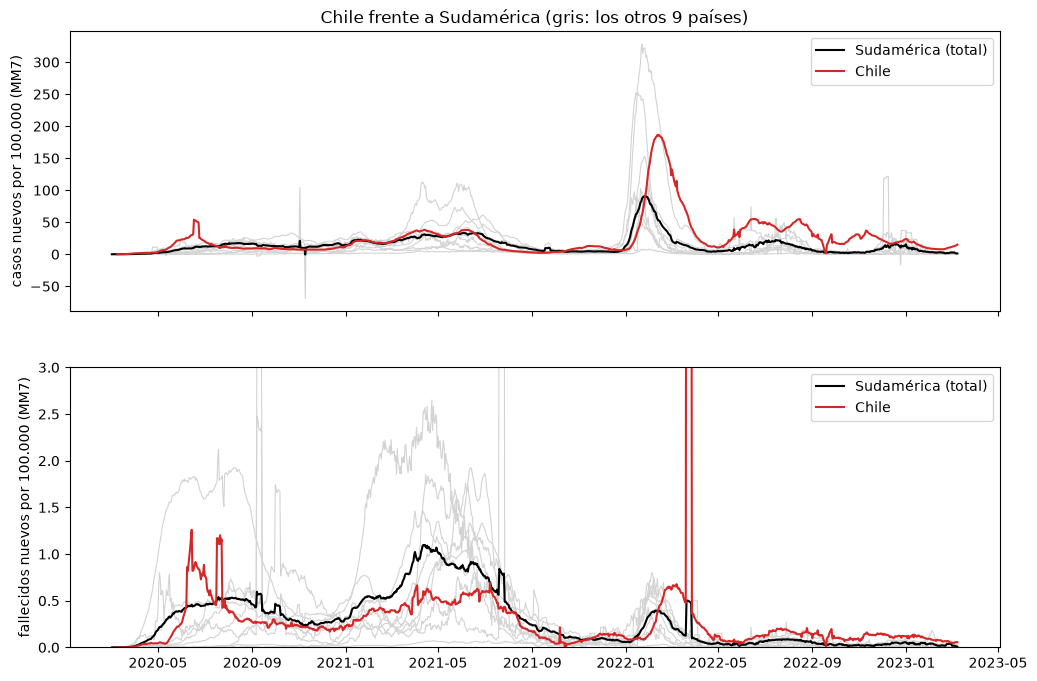

In [8]:
# Media móvil de 7 días por 100.000: Chile, el total de la región y cada país en gris
fig, ejes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for eje, medida in zip(ejes, ["casos", "fallecidos"]):
    for pais in SUDAMERICA:
        if pais != "Chile":
            serie = sudamerica[sudamerica["pais"] == pais]
            eje.plot(serie["fecha"], media_movil_7(tasa_100k(serie[f"{medida}_nuevos"], serie["poblacion"])),
                     color="lightgray", linewidth=0.8)
    eje.plot(region["fecha"], media_movil_7(tasa_100k(region[f"{medida}_nuevos"], region["poblacion"])),
             color="black", label="Sudamérica (total)")
    eje.plot(chile["fecha"], media_movil_7(tasa_100k(chile[f"{medida}_nuevos"], chile["poblacion"])),
             color="tab:red", label="Chile")
    eje.set_ylabel(f"{medida} nuevos por 100.000 (MM7)")
    eje.legend()
ejes[0].set_title("Chile frente a Sudamérica (gris: los otros 9 países)")
ejes[1].set_ylim(0, 3)  # se corta en 3: las cargas en bloque de fallecidos aplastan el resto
plt.show()

### Las olas de Chile
**Definición:** una ola es un período de **al menos 14 días seguidos** en que la media móvil de 7 días de casos nuevos
supera **15 por 100.000** (en Chile, unos 2.900 casos diarios). Empieza el primer día sobre el umbral y termina el
último. La **peor ola** es la de más fallecidos por 100.000.

El umbral es una decisión del equipo. La tabla siguiente prueba varios: con 10, ómicron y la ola de mitad de 2022 quedan
como una sola (ene–sep 2022); con 20, la ola de 2021 se parte en dos; con 25, la primera ola dura menos de un mes y la de
fines de 2022 queda reducida a noviembre. 15 es el valor que separa las olas sin trozarlas.

In [9]:
def detectar_olas(serie, umbral=15, dias_minimos=14):
    """Períodos de al menos dias_minimos días con media móvil de casos por 100.000 sobre el umbral."""
    serie = serie.copy()
    serie["mm7_100k"] = media_movil_7(tasa_100k(serie["casos_nuevos"], serie["poblacion"]))
    sobre = serie["mm7_100k"] > umbral
    tramo = (sobre != sobre.shift()).cumsum()  # cambia de número cada vez que cruza el umbral
    olas = serie[sobre].groupby(tramo[sobre]).agg(
        inicio=("fecha", "min"), fin=("fecha", "max"), dias=("fecha", "size"),
        casos=("casos_nuevos", "sum"), fallecidos=("fallecidos_nuevos", "sum"), pico_mm7_100k=("mm7_100k", "max"))
    olas = olas[olas["dias"] >= dias_minimos].reset_index(drop=True)
    poblacion = serie["poblacion"].max()
    olas["casos_100k"] = tasa_100k(olas["casos"], poblacion)
    olas["fallecidos_100k"] = tasa_100k(olas["fallecidos"], poblacion)
    olas.index = olas.index + 1
    return olas


# Qué olas salen con cada umbral
prueba = []
for umbral in [10, 15, 20, 25]:
    olas = detectar_olas(chile, umbral)
    periodos = olas["inicio"].dt.strftime("%m/%Y") + "–" + olas["fin"].dt.strftime("%m/%Y")
    prueba.append({"umbral": umbral, "olas": len(olas), "períodos": ", ".join(periodos)})
pd.DataFrame(prueba)

,umbral,olas,períodos
0,10,6,"05/2020–07/2020, 07/2020–08/2020, 12/2020–07/2..."
1,15,5,"05/2020–07/2020, 01/2021–07/2021, 01/2022–04/2..."
2,20,6,"05/2020–07/2020, 01/2021–02/2021, 03/2021–06/2..."
3,25,5,"06/2020–06/2020, 03/2021–06/2021, 01/2022–04/2..."


In [10]:
olas_chile = detectar_olas(chile)

# El 21-mar-2022 entran 11.447 fallecidos de una vez (sección 1): se muestra la ola con y sin esa carga
carga = chile.loc[chile["fecha"] == "2022-03-21", "fallecidos_nuevos"].iloc[0]
en_ola = (olas_chile["inicio"] <= "2022-03-21") & (olas_chile["fin"] >= "2022-03-21")
olas_chile["fallecidos_100k_sin_carga"] = olas_chile["fallecidos_100k"]
olas_chile.loc[en_ola, "fallecidos_100k_sin_carga"] = tasa_100k(
    olas_chile.loc[en_ola, "fallecidos"] - carga, chile["poblacion"].max())
olas_chile.round({"pico_mm7_100k": 1, "casos_100k": 1, "fallecidos_100k": 1, "fallecidos_100k_sin_carga": 1})

,inicio,fin,dias,casos,fallecidos,pico_mm7_100k,casos_100k,fallecidos_100k,fallecidos_100k_sin_carga
1,2020-05-21,2020-07-11,52,258412.0,6337.0,53.9,1351.8,33.1,33.1
2,2021-01-07,2021-07-08,183,954108.0,16698.0,38.3,4991.1,87.3,87.3
3,2022-01-10,2022-04-15,96,1696408.0,17933.0,186.5,8874.2,93.8,33.9
4,2022-05-11,2022-09-14,127,985268.0,3180.0,55.2,5154.1,16.6,16.6
5,2022-09-21,2023-01-16,118,500872.0,2591.0,36.9,2620.1,13.6,13.6


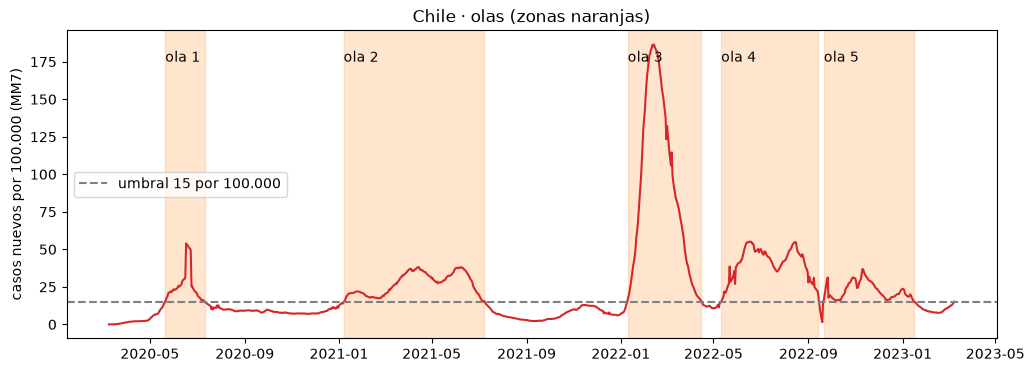

In [11]:
mm7 = media_movil_7(tasa_100k(chile["casos_nuevos"], chile["poblacion"]))
fig, eje = plt.subplots(figsize=(12, 4))
eje.plot(chile["fecha"], mm7, color="tab:red")
eje.axhline(15, color="gray", linestyle="--", label="umbral 15 por 100.000")
for numero, ola in olas_chile.iterrows():
    eje.axvspan(ola["inicio"], ola["fin"], color="tab:orange", alpha=0.2)
    eje.text(ola["inicio"], 175, f"ola {numero}")
eje.set_ylabel("casos nuevos por 100.000 (MM7)")
eje.set_title("Chile · olas (zonas naranjas)")
eje.legend()
plt.show()

### Respuesta a P1
**Chile frente a Sudamérica**
- En **casos**, Chile es **2.º de 10** con 27.162 por 100.000 (1,7 veces el total de la región, 15.803); solo lo supera Uruguay.
- En **fallecidos**, Chile es **2.º** con 336 por 100.000 (región: 314). Perú es lejos el peor (666).
  Pero 60 de esos 336 son la carga en bloque del 21-mar-2022: sin ella Chile queda en 276 por 100.000, bajo el total de la
  región y en el puesto 6. (Otros países también tienen cargas en bloque, los picos grises del gráfico; no las revisamos una por una.)
- **Por año** la historia cambia: en 2020 y 2021 Chile estuvo en la media de la región en casos y **bajo ella en fallecidos**
  (2021: 118 contra 180 por 100.000). En **2022** Chile tuvo **2,7 veces** los casos de la región (16.902 contra 6.276 por 100.000)
  y también más fallecidos (126 contra 35; 66 sin la carga en bloque). Parte de esa diferencia puede ser más testeo y
  mejor registro en Chile, no solo más contagio (advertencia de H4.3).

**Las olas de Chile:** con el criterio elegido, Chile tuvo **5 olas**:

| Ola | Período | Casos por 100.000 | Fallecidos por 100.000 |
|---|---|---|---|
| 1 | 21-may → 11-jul-2020 | 1.352 | 33,1 |
| 2 | 7-ene → 8-jul-2021 | 4.991 | 87,3 |
| 3 (ómicron) | 10-ene → 15-abr-2022 | 8.874 (pico 186,5 diarios) | 93,8 (33,9 sin la carga) |
| 4 | 11-may → 14-sep-2022 | 5.154 | 16,6 |
| 5 | 21-sep-2022 → 16-ene-2023 | 2.620 | 13,6 |

**¿Cuál fue la peor?**
- En **casos**, ómicron: tuvo más casos en 3 meses que las olas 1 y 2 juntas.
- En **fallecidos**, la respuesta depende de la carga en bloque. Con ella, ómicron (93,8); sin ella, la **ola 2 de 2021**
  (87,3 contra 33,9). Esos 11.447 fallecidos no son muertes de marzo de 2022, así que la peor ola en vidas fue la de **2021**.
  Su letalidad aparente fue 1,8 %, contra 0,4 % en ómicron.

## 3 · P2: ¿Qué regiones de Chile fueron más golpeadas y en qué ola? (H5.3)
Chile se informa por región desde el 20-may-2020; se usa **desde el 1-jun-2020**, como pide el enunciado.
Aquí no hace falta la opción C: dentro de cada región los `casos_nuevos` del DW ya son el acumulado menos el día anterior.
La región `Unknown` (casos sin región asignada, 41 en total) no tiene población y queda fuera de las tasas.
La población y la ubicación (lat/long) de cada región vienen de la tabla UID.

In [12]:
REGIONES_CHILE = """
    SELECT t.region_estado AS region, t.poblacion, t.lat, t.long, d.fecha,
           f.casos_nuevos, f.fallecidos_nuevos
    FROM fact_covid f
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    WHERE t.pais = 'Chile' AND t.nivel = 'region' AND d.fecha >= '2020-06-01'
"""
regiones = pd.read_sql(REGIONES_CHILE, dw, parse_dates=["fecha"])

# Control: casos desde junio + acumulado al 31-may = acumulado final de Chile
al_31_mayo = chile.loc[chile["fecha"] == "2020-05-31", "casos_acumulados"].iloc[0]
print("Casos desde jun-2020 + acumulado al 31-may:", f"{regiones['casos_nuevos'].sum() + al_31_mayo:,.0f}",
      "· acumulado final:", f"{chile['casos_acumulados'].iloc[-1]:,.0f}")

regiones = regiones[regiones["region"] != "Unknown"]
print("Regiones:", regiones["region"].nunique())

Casos desde jun-2020 + acumulado al 31-may: 5,192,286 · acumulado final: 5,192,286
Regiones: 16


### Total desde junio de 2020

In [13]:
total_region = regiones.groupby(["region", "poblacion", "lat", "long"])[["casos_nuevos", "fallecidos_nuevos"]].sum().reset_index()
total_region["casos_100k"] = tasa_100k(total_region["casos_nuevos"], total_region["poblacion"])
total_region["fallecidos_100k"] = tasa_100k(total_region["fallecidos_nuevos"], total_region["poblacion"])
total_region["puesto_casos"] = total_region["casos_100k"].rank(ascending=False).astype(int)
total_region["puesto_fallecidos"] = total_region["fallecidos_100k"].rank(ascending=False).astype(int)
total_region = total_region.sort_values("casos_100k", ascending=False)
total_region[["region", "poblacion", "casos_100k", "fallecidos_100k", "puesto_casos", "puesto_fallecidos"]].round(1)

,region,poblacion,casos_100k,fallecidos_100k,puesto_casos,puesto_fallecidos
3,Atacama,288944.0,40401.3,248.5,1,15
9,Magallanes,166533.0,39990.3,453.4,2,1
8,Los Rios,384837.0,38430.8,365.1,3,4
4,Aysen,103158.0,35222.7,215.2,4,16
2,Arica y Parinacota,226068.0,34989.0,395.0,5,3
14,Tarapaca,330558.0,33634.3,348.5,6,6
10,Maule,1044950.0,33064.5,319.5,7,7
12,Nuble,480609.0,32687.3,272.6,8,13
5,Biobio,1556805.0,32679.2,309.2,9,10
1,Araucania,957224.0,30459.0,300.3,10,12


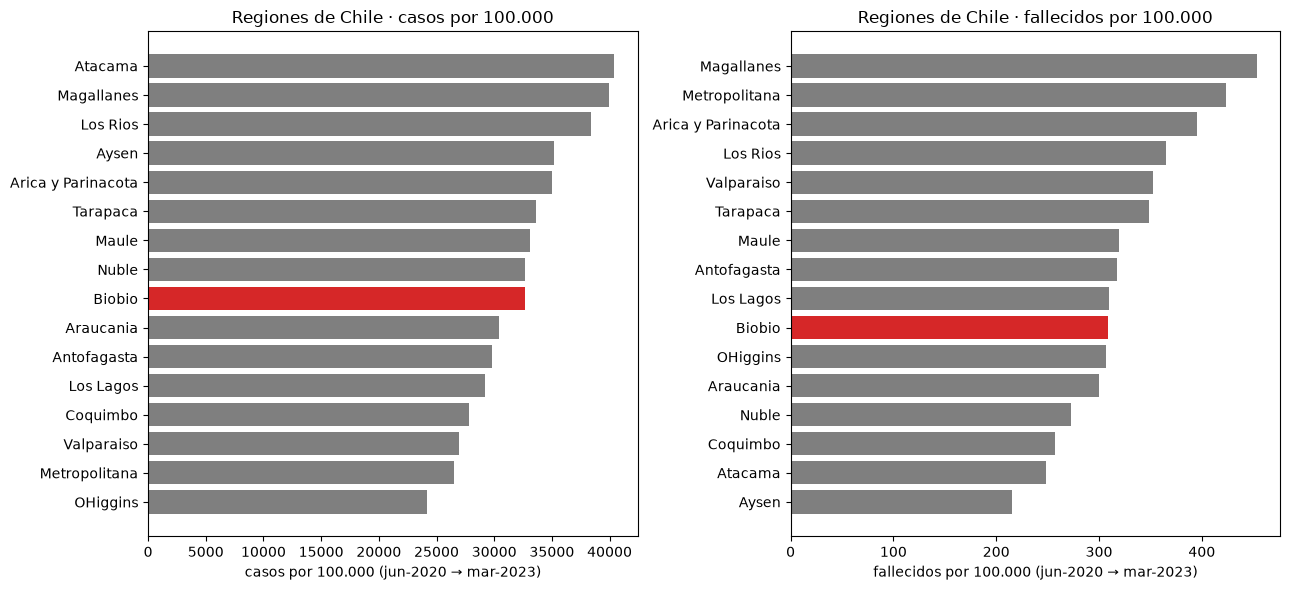

In [14]:
# Ranking por 100.000; Biobío en rojo
fig, ejes = plt.subplots(1, 2, figsize=(13, 6))
for eje, medida in zip(ejes, ["casos_100k", "fallecidos_100k"]):
    orden = total_region.sort_values(medida)
    colores = ["tab:red" if region == "Biobio" else "tab:gray" for region in orden["region"]]
    eje.barh(orden["region"], orden[medida], color=colores)
    eje.set_xlabel(medida.replace("_100k", " por 100.000") + " (jun-2020 → mar-2023)")
ejes[0].set_title("Regiones de Chile · casos por 100.000")
ejes[1].set_title("Regiones de Chile · fallecidos por 100.000")
plt.tight_layout()
plt.show()

### Mapa regional
Burbujas en la latitud y longitud de la tabla UID: el **tamaño** es la incidencia (casos por 100.000) y el **color**
los fallecidos por 100.000.

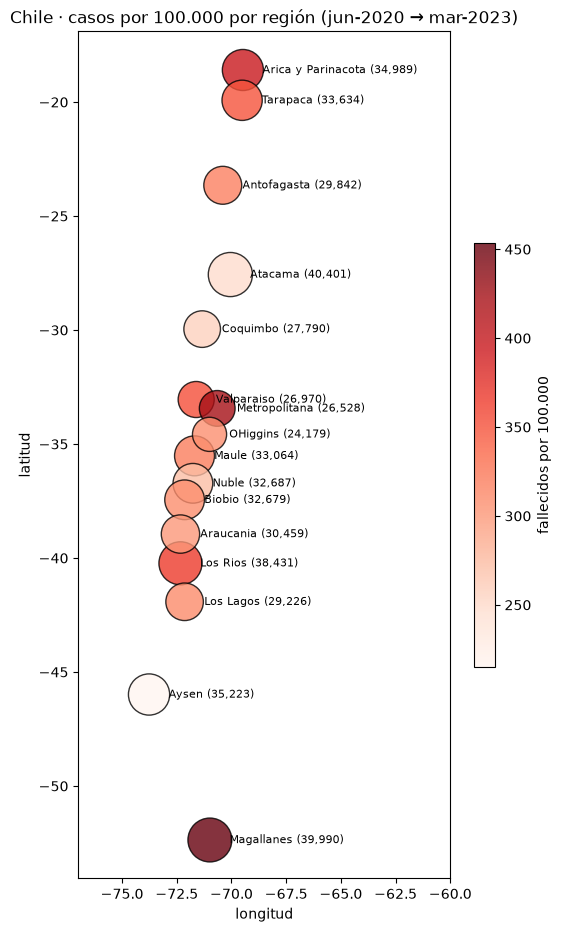

In [15]:
fig, eje = plt.subplots(figsize=(6, 11))
puntos = eje.scatter(total_region["long"], total_region["lat"], s=total_region["casos_100k"] / 40,
                     c=total_region["fallecidos_100k"], cmap="Reds", edgecolor="black", alpha=0.8)
for _, fila in total_region.iterrows():
    eje.text(fila["long"] + 0.9, fila["lat"], f"{fila['region']} ({fila['casos_100k']:,.0f})", va="center", fontsize=8)
fig.colorbar(puntos, label="fallecidos por 100.000", shrink=0.5)
eje.set_xlim(-77, -60)
eje.set_xlabel("longitud")
eje.set_ylabel("latitud")
eje.set_title("Chile · casos por 100.000 por región (jun-2020 → mar-2023)")
plt.show()

### Por ola
Se usan las 5 olas de Chile de la sección 2 (la ola 1 se cuenta desde el 1-jun-2020).
Los fallecidos **del 21-mar-2022 no se cuentan en ninguna ola**: es la carga en bloque de 11.447 fallecidos
(sección 1), repartida entre todas las regiones, y no se sabe a qué ola pertenecen.

In [16]:
filas = []
for numero, ola in olas_chile.iterrows():
    en_ola = regiones[(regiones["fecha"] >= ola["inicio"]) & (regiones["fecha"] <= ola["fin"])].copy()
    en_ola.loc[en_ola["fecha"] == "2022-03-21", "fallecidos_nuevos"] = 0  # la carga en bloque no se cuenta
    suma = en_ola.groupby(["region", "poblacion"])[["casos_nuevos", "fallecidos_nuevos"]].sum().reset_index()
    suma["ola"] = numero
    filas.append(suma)
por_ola = pd.concat(filas)
por_ola["casos_100k"] = tasa_100k(por_ola["casos_nuevos"], por_ola["poblacion"])
por_ola["fallecidos_100k"] = tasa_100k(por_ola["fallecidos_nuevos"], por_ola["poblacion"])

casos_ola = por_ola.pivot(index="region", columns="ola", values="casos_100k").round(0)
fallecidos_ola = por_ola.pivot(index="region", columns="ola", values="fallecidos_100k").round(1)
fallecidos_ola["peor ola"] = fallecidos_ola.idxmax(axis=1)
print("Casos por 100.000 por ola")
display(casos_ola)
print("Fallecidos por 100.000 por ola (sin la carga del 21-mar-2022)")
fallecidos_ola

Casos por 100.000 por ola


ola,1,2,3,4,5
region,,,,,
Antofagasta,1493.0,5545.0,8901.0,6709.0,2655.0
Araucania,155.0,7311.0,11414.0,4783.0,2584.0
Arica y Parinacota,786.0,6414.0,11132.0,7225.0,3047.0
Atacama,451.0,5786.0,11876.0,11762.0,4574.0
Aysen,33.0,5999.0,13960.0,5958.0,3760.0
Biobio,406.0,6146.0,11662.0,5866.0,3310.0
Coquimbo,449.0,4148.0,9244.0,7560.0,2794.0
Los Lagos,164.0,7014.0,11343.0,3447.0,1749.0
Los Rios,106.0,9593.0,13291.0,6088.0,3783.0


Fallecidos por 100.000 por ola (sin la carga del 21-mar-2022)


ola,1,2,3,4,5,peor ola
region,,,,,,
Antofagasta,30.8,91.8,28.3,18.3,9.4,2
Araucania,0.0,99.3,42.6,14.2,15.8,2
Arica y Parinacota,8.4,116.8,53.1,19.5,13.7,2
Atacama,3.1,60.6,27.7,30.8,10.4,2
Aysen,0.0,48.5,53.3,14.5,13.6,3
Biobio,3.9,99.8,44.9,14.5,15.2,2
Coquimbo,3.8,72.6,34.8,19.9,12.0,2
Los Lagos,1.1,117.7,47.3,12.3,13.8,2
Los Rios,1.3,120.8,65.2,21.3,20.3,2


In [17]:
# Región más golpeada en cada ola y puesto de Biobío
resumen_ola = []
for numero in olas_chile.index:
    ola = por_ola[por_ola["ola"] == numero]
    puesto_casos = ola["casos_100k"].rank(ascending=False)
    puesto_fallecidos = ola["fallecidos_100k"].rank(ascending=False)
    biobio = ola["region"] == "Biobio"
    resumen_ola.append({
        "ola": numero,
        "más casos por 100.000": ola.loc[ola["casos_100k"].idxmax(), "region"],
        "más fallecidos por 100.000": ola.loc[ola["fallecidos_100k"].idxmax(), "region"],
        "Biobío · puesto casos": int(puesto_casos[biobio].iloc[0]),
        "Biobío · puesto fallecidos": int(puesto_fallecidos[biobio].iloc[0]),
    })
pd.DataFrame(resumen_ola)

,ola,más casos por 100.000,más fallecidos por 100.000,Biobío · puesto casos,Biobío · puesto fallecidos
0,1,Metropolitana,Metropolitana,10,8
1,2,Los Rios,Magallanes,8,6
2,3,Aysen,Los Rios,7,8
3,4,Atacama,Atacama,11,13
4,5,Atacama,Nuble,5,6


### Respuesta a P2
**Total desde junio de 2020** (16 regiones):
- **Casos:** Atacama (40.401 por 100.000), Magallanes (39.990) y Los Ríos (38.431) son las más golpeadas. O'Higgins
  (24.179) y la Metropolitana (26.528) son las de menos casos.
- **Fallecidos:** Magallanes (453 por 100.000), la **Metropolitana (423)** y Arica y Parinacota (395) son las peores.
  Aysén (215) y Atacama (249) son las de menos fallecidos.
- **Hallazgo:** casos y fallecidos no van juntos. Atacama es 1.ª en casos y 15.ª en fallecidos, y la Metropolitana es 15.ª en
  casos y 2.ª en fallecidos. La Metropolitana carga sus fallecidos en la **ola 1** (69,9 por 100.000, más del doble que
  cualquier otra región), cuando el virus llegó primero a Santiago.
- Estos totales incluyen la carga en bloque del 21-mar-2022. Si se descuenta, el orden casi no cambia (Biobío pasa del
  10.º al 9.º lugar).

**Biobío** queda a **mitad de tabla**: 9.º de 16 en casos (32.679 por 100.000) y 10.º en fallecidos (309).
Su peor ola en fallecidos fue la 2 (99,8 por 100.000) y en casos la 3, ómicron (11.662). Por ola, su puesto en casos va
del 5.º (ola 5) al 11.º (ola 4).

**¿En qué ola?**
- **Ola 1 (jun–jul-2020):** la Metropolitana y el norte (Antofagasta, Tarapacá). Ojo, solo se cuenta desde el 1-jun.
- **Ola 2 (2021):** fue la **peor ola en fallecidos para 15 de las 16 regiones** (solo Aysén tuvo más en ómicron). Golpeó
  más al sur y al extremo norte: Magallanes 139,9, Tarapacá 138,9 y Los Ríos 120,8 fallecidos por 100.000.
- **Ola 3 (ómicron):** fue la de más casos en todas las regiones; Aysén llegó a 13.960 por 100.000.
- **Olas 4 y 5 (2022):** Atacama tuvo en la ola 4 casi tantos casos como en ómicron (11.762 contra 11.876).

## 4 · P3: ¿Cómo cambió la letalidad aparente antes y después de la vacunación? (H5.4)
**Letalidad aparente del mes** = fallecidos nuevos del mes ÷ casos nuevos del mes × 100. Es "aparente" porque solo
cuenta los casos **detectados** (advertencia de H4.3).
Se cruza con el **% de la población con esquema completo** (OWID, `fact_vacunacion`), tomando el valor más alto del mes
(es acumulado, así que es el de fin de mes).

Países: **Chile, Argentina, Perú y Brasil** (los mismos del dice de H3.4). Las series ya están cargadas en la sección 2.
En Chile no se cuentan los fallecidos del 21-mar-2022 (la carga en bloque de la sección 1).

In [18]:
PAISES_P3 = ["Chile", "Argentina", "Peru", "Brazil"]

VACUNACION = """
    SELECT t.pais, d.fecha, v.pct_esquema_completo
    FROM fact_vacunacion v
    JOIN dim_territorio t ON t.territorio_key = v.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = v.fecha_key
    WHERE t.pais IN ('Chile', 'Argentina', 'Peru', 'Brazil')
"""
vacunacion = pd.read_sql(VACUNACION, dw, parse_dates=["fecha"])
vacunacion["mes"] = vacunacion["fecha"].dt.to_period("M")
vacunacion_mes = vacunacion.groupby(["pais", "mes"])["pct_esquema_completo"].max().reset_index()

diario = sudamerica[sudamerica["pais"].isin(PAISES_P3)].copy()
carga_chile = (diario["pais"] == "Chile") & (diario["fecha"] == "2022-03-21")
diario.loc[carga_chile, "fallecidos_nuevos"] = 0  # la carga en bloque no se cuenta
diario["mes"] = diario["fecha"].dt.to_period("M")

mensual = diario.groupby(["pais", "mes"])[["casos_nuevos", "fallecidos_nuevos"]].sum().reset_index()
mensual = mensual.merge(vacunacion_mes, on=["pais", "mes"], how="left")
mensual = mensual[mensual["casos_nuevos"] > 0]  # Brasil tiene enero y febrero de 2020 sin casos
mensual["letalidad"] = mensual["fallecidos_nuevos"] / mensual["casos_nuevos"] * 100
mensual[mensual["pais"] == "Chile"].round({"pct_esquema_completo": 1, "letalidad": 2})

,pais,mes,casos_nuevos,fallecidos_nuevos,pct_esquema_completo,letalidad
76,Chile,2020-03,2738.0,12.0,NaN,0.44
77,Chile,2020-04,13285.0,215.0,NaN,1.62
78,Chile,2020-05,83665.0,827.0,NaN,0.99
79,Chile,2020-06,179705.0,4634.0,NaN,2.58
80,Chile,2020-07,76274.0,3769.0,NaN,4.94
81,Chile,2020-08,56059.0,1832.0,NaN,3.27
82,Chile,2020-09,51265.0,1452.0,NaN,2.83
83,Chile,2020-10,47265.0,1466.0,NaN,3.10
84,Chile,2020-11,41487.0,1203.0,NaN,2.90
85,Chile,2020-12,57230.0,1198.0,NaN,2.09


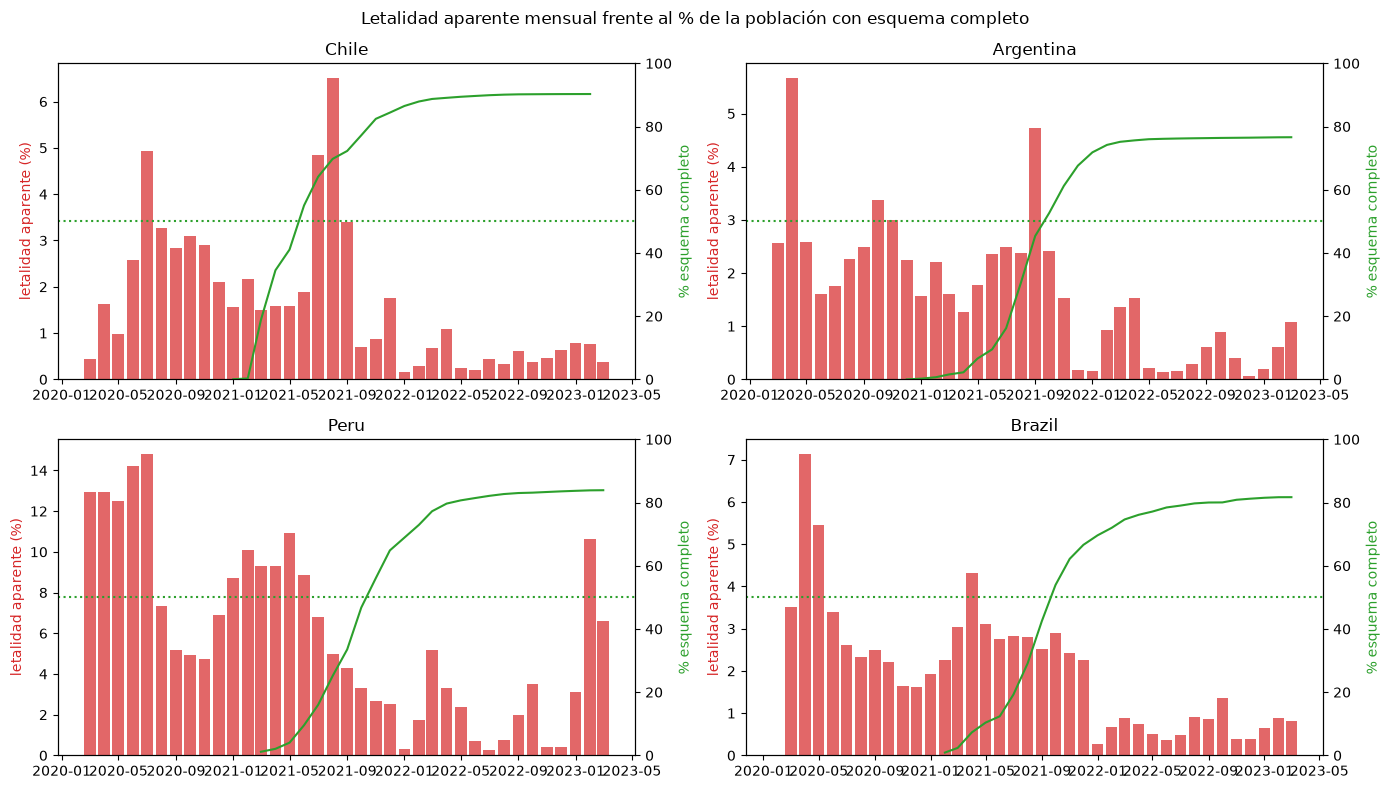

In [19]:
# Letalidad mensual (barras) y % con esquema completo (línea, eje derecho)
fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
for eje, pais in zip(ejes.flatten(), PAISES_P3):
    datos = mensual[mensual["pais"] == pais]
    fechas = datos["mes"].dt.to_timestamp()
    eje.bar(fechas, datos["letalidad"], width=25, color="tab:red", alpha=0.7)
    eje.set_ylabel("letalidad aparente (%)", color="tab:red")
    eje_vacuna = eje.twinx()
    eje_vacuna.plot(fechas, datos["pct_esquema_completo"], color="tab:green")
    eje_vacuna.axhline(50, color="tab:green", linestyle=":")
    eje_vacuna.set_ylim(0, 100)
    eje_vacuna.set_ylabel("% esquema completo", color="tab:green")
    eje.set_title(pais)
fig.suptitle("Letalidad aparente mensual frente al % de la población con esquema completo")
plt.tight_layout()
plt.show()

### Antes y después
Cada mes se clasifica por el % con esquema completo a fin de mes: **sin vacunación** (todavía sin dato de OWID),
**vacunando** (menos de 50 %) y **50 % o más**. Este último se separa en **antes de ómicron** y **desde ómicron**
(1-dic-2021, la misma fecha de la P7): ómicron llegó cuando los cuatro países ya pasaban el 50 % y por sí sola cambió
la letalidad, así que sin separarlo se le atribuiría todo a la vacuna.
La letalidad del período es la suma de fallecidos ÷ la suma de casos del período (no el promedio de los meses, para que
los meses con pocos casos no pesen igual que los grandes).

In [20]:
def periodo(fila):
    if fila["mes"] >= pd.Period("2021-12", "M"):
        return "4 · 50 % o más, desde ómicron"  # los 4 países ya pasaban el 50 % (Chile en mar-2023 no tiene dato: 90 %)
    if pd.isna(fila["pct_esquema_completo"]):
        return "1 · sin vacunación"
    if fila["pct_esquema_completo"] < 50:
        return "2 · vacunando (< 50 %)"
    return "3 · 50 % o más, antes de ómicron"


mensual["periodo"] = mensual.apply(periodo, axis=1)

por_periodo = mensual.groupby(["pais", "periodo"])[["casos_nuevos", "fallecidos_nuevos"]].sum()
por_periodo["letalidad"] = por_periodo["fallecidos_nuevos"] / por_periodo["casos_nuevos"] * 100
por_periodo["letalidad"].unstack().round(2)

periodo,1 · sin vacunación,2 · vacunando (< 50 %),"3 · 50 % o más, antes de ómicron","4 · 50 % o más, desde ómicron"
pais,,,,
Argentina,2.72,1.99,1.91,0.29
Brazil,2.44,3.05,2.69,0.56
Chile,2.73,1.64,2.39,0.42
Peru,9.25,8.86,2.69,0.82


### Respuesta a P3
**La letalidad aparente bajó entre 4 y 11 veces** entre el período sin vacunación y el período con 50 % o más
desde ómicron:

| País | Sin vacunación | Desde ómicron (≥ 50 %) | Cuántas veces menos |
|---|---|---|---|
| Chile | 2,73 % | 0,42 % | 6,5 |
| Argentina | 2,72 % | 0,29 % | 9,4 |
| Brasil | 2,44 % | 0,56 % | 4,4 |
| Perú | 9,25 % | 0,82 % | 11,3 |

**Pero la caída no llega cuando se pasa el 50 %, sino con ómicron** (hallazgo):
- En los meses con 50 % o más **antes** de ómicron, la letalidad seguía entre 1,9 % y 2,7 %. En Chile incluso subió
  (2,39 % contra 1,64 % mientras se vacunaba).
- En **enero de 2022** se desploma en los cuatro países a la vez (0,15 % a 0,33 %), cuando la vacunación llevaba meses estable.

**Por qué no se puede decir "la vacuna bajó la letalidad X veces":**
- **Rezago caso → fallecido.** Una persona muere semanas después de ser un caso. Cuando una ola baja rápido, el mes
  tiene pocos casos nuevos y todavía muchos fallecidos de antes. Así se explican los meses de 4,9 % y 6,5 % de Chile en
  jul–ago-2021: no fueron meses más letales, son la cola de la ola 2.
- **Testeo (advertencia de H4.3).** Con ómicron hubo testeo masivo, así que se detectaron muchos más casos leves y el
  denominador creció. Perú tiene una letalidad mucho más alta en todo el período porque detectó pocos casos (y,
  probablemente, por un criterio más amplio para contar un fallecido COVID).
- **La variante.** Ómicron fue en general menos grave, y además llegó cuando mucha gente ya se había contagiado antes.
- El período "50 % o más, antes de ómicron" es corto: 6 meses en Chile, 2 en Argentina y Brasil y 1 en Perú.

**Conclusión:** la letalidad aparente de hoy es una fracción de la de 2020 en los cuatro países, y el cambio coincide con
la vacunación masiva. Pero con estos datos **no se puede separar el efecto de la vacuna** del de ómicron y el testeo.
Es una correlación en el tiempo, no una causa medida.

## 5 · P4: ¿Qué tan confiables son los datos de cada país? (H5.5)
Se usa el **índice de calidad de H2.4** (`data/clean/indice_calidad_pais.parquet`, lo deja `02_calidad`).
Recordatorio de cómo se calculó: 6 indicadores, cada uno es la proporción de días del país con un problema; se dividen por
su máximo entre los 196 países y el índice es **100 × (1 − promedio de los 6)**. 100 = sin problemas.
El ranking considera solo países con **1 millón de habitantes o más** (157), igual que en H2.4.

Para explicar **por qué** un país sale mal, se miran los **puntos que pierde** por cada indicador
(indicador normalizado ÷ 6 × 100): la suma de los puntos perdidos es 100 − índice.

In [21]:
indice = pd.read_parquet("../data/clean/indice_calidad_pais.parquet").set_index("country_region")
INDICADORES = ["retrocesos", "sin_reporte", "ausente", "picos", "fallecidos_mayor", "serie_distinta"]

puntos_perdidos = indice[INDICADORES] / indice[INDICADORES].max() / len(INDICADORES) * 100
grandes = indice[indice["poblacion"] >= 1_000_000]
print("Países con 1 millón o más:", len(grandes), "· índice promedio:", round(grandes["indice_calidad"].mean(), 1))
print("Chile:", indice.loc["Chile", "indice_calidad"],
      "· puesto", int(grandes["indice_calidad"].rank(ascending=False)["Chile"]), "de", len(grandes), "(1 = mejor)")

peores = grandes.nsmallest(10, "indice_calidad").index
tabla_peores = puntos_perdidos.loc[peores].round(1)
tabla_peores["indice_calidad"] = indice.loc[peores, "indice_calidad"]
tabla_peores["problema principal"] = puntos_perdidos.loc[peores].idxmax(axis=1)
tabla_peores

Países con 1 millón o más: 157 · índice promedio: 89.9
Chile: 96.6 · puesto 34 de 157 (1 = mejor)


,retrocesos,sin_reporte,ausente,picos,fallecidos_mayor,serie_distinta,indice_calidad,problema principal
country_region,,,,,,,,
Colombia,0.4,4.3,16.2,8.7,0.9,1.1,68.3,ausente
Botswana,1.1,13.1,0.0,16.7,0.0,0.0,69.1,picos
Germany,16.7,1.9,0.0,0.7,0.0,11.5,69.2,retrocesos
Cameroon,0.4,13.7,0.0,16.3,0.0,0.0,69.6,picos
Sweden,2.7,9.0,0.0,12.8,0.0,2.8,72.6,picos
Mexico,2.1,3.1,13.5,6.8,0.0,0.7,73.8,ausente
Mauritius,0.0,10.9,0.0,13.9,0.0,0.3,74.9,picos
Congo (Brazzaville),0.7,14.1,0.0,10.0,0.0,0.0,75.1,sin_reporte
Switzerland,6.3,7.1,0.0,11.5,0.0,0.0,75.1,picos


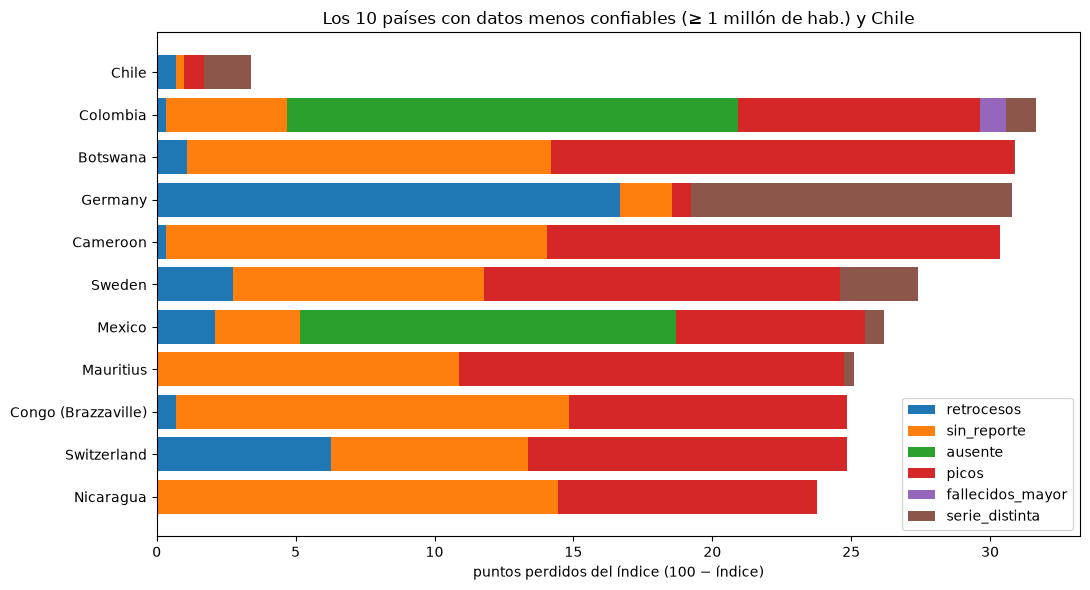

In [22]:
# Puntos que pierde cada país por indicador (los 10 peores y Chile como referencia)
paises_grafico = list(peores[::-1]) + ["Chile"]
datos = puntos_perdidos.loc[paises_grafico]
fig, eje = plt.subplots(figsize=(11, 6))
izquierda = pd.Series(0.0, index=paises_grafico)
for indicador in INDICADORES:
    eje.barh(paises_grafico, datos[indicador], left=izquierda, label=indicador)
    izquierda = izquierda + datos[indicador]
eje.set_xlabel("puntos perdidos del índice (100 − índice)")
eje.set_title("Los 10 países con datos menos confiables (≥ 1 millón de hab.) y Chile")
eje.legend()
plt.tight_layout()
plt.show()

### Cómo se ve el problema principal
Los indicadores que más pesan son `sin_reporte` (el acumulado no cambia ese día) y `picos`, que van juntos: lo que no
se informa unos días llega de golpe el día del informe. Mirando **qué día de la semana** falta el reporte
(`dim_fecha` del DW) se ve que no son huecos al azar: son países que pasaron a informar uno o dos días por semana.

In [23]:
SIN_REPORTE_SEMANA = """
    SELECT t.pais, d.anio, d.dia_semana, AVG(f.sin_reporte) * 100 AS pct_dias_sin_reporte
    FROM fact_covid f
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    WHERE t.pais IN ('Nicaragua', 'Botswana', 'Switzerland') AND t.nivel = 'pais'
    GROUP BY t.pais, d.anio, d.dia_semana
"""
semana = pd.read_sql(SIN_REPORTE_SEMANA, dw)
dias = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
semana.pivot_table(index=["pais", "anio"], columns="dia_semana", values="pct_dias_sin_reporte")[dias].round(0)

dia_semana        lunes  martes  miércoles  jueves  viernes  sábado  domingo
pais        anio                                                            
Botswana    2020   45.0    88.0       85.0    45.0     85.0    97.0     85.0
            2021    6.0    92.0      100.0     6.0     94.0   100.0    100.0
            2022   69.0    79.0       90.0    67.0     92.0   100.0     98.0
            2023   20.0    60.0      100.0   100.0    100.0   100.0    100.0
Nicaragua   2020   93.0    95.0       32.0    76.0     95.0    95.0     98.0
            2021  100.0   100.0        0.0   100.0    100.0   100.0    100.0
            2022   98.0    98.0       17.0    98.0     98.0   100.0    100.0
            2023  100.0   100.0       30.0    90.0    100.0    89.0    100.0
Switzerland 2020    2.0     0.0        2.0     2.0      5.0    34.0     34.0
            2021    6.0     2.0        2.0     2.0      9.0    96.0    100.0
            2022   73.0     4.0       75.0    73.0     75.0   100.0     98.0
            2023   90.0    20.0      100.0    90.0    100.0   100.0    100.0

### Respuesta a P4
**En general los datos son razonables:** el índice promedio de los 157 países es 89,9 y la mitad supera 91,2.
**Chile tiene 96,6** (puesto 34 de 157): pierde pocos puntos, sobre todo porque su serie no coincide con los reportes
algunos días (`serie_distinta`).

**Los 10 menos confiables y por qué:**

| País | Índice | Por qué |
|---|---|---|
| Colombia | 68,3 | **Falta del archivo** el 3,7 % de los días (de los más altos entre países), además de días sin reporte y picos |
| Botsuana | 69,1 | Informes espaciados (78 % de días sin cambio) → **picos** cuando llega el informe |
| Alemania | 69,2 | **Retrocesos** (4,3 % de sus días, el máximo) y la serie no coincide con los reportes el 66 % de los días |
| Camerún | 69,6 | Informes espaciados (81 % sin cambio) y picos |
| Suecia | 72,6 | 54 % de días sin cambio, picos y serie distinta |
| México | 73,8 | **Falta del archivo** el 3,1 % de los días, además de picos |
| Mauricio | 74,9 | Informes espaciados (65 % sin cambio) y picos |
| Congo | 75,1 | Informes espaciados (84 % sin cambio) |
| Suiza | 75,1 | Sin informe los fines de semana (2021) y semanal desde 2022, además de retrocesos |
| Nicaragua | 76,2 | **Un informe por semana** (los miércoles) desde 2021: 86 % de días sin cambio |

Hay **dos tipos de problema**:
1. **Países que informan poco seguido** (Nicaragua, Botsuana, Camerún, Congo, Mauricio, Suiza, Suecia). El dato existe,
   pero llega agrupado: el día del informe parece un pico y los otros días parecen cero.
2. **Países con datos que se corrigen o faltan** (Alemania, Colombia, México). El acumulado baja, la serie histórica
   difiere de los reportes diarios o el país desaparece algunos días del archivo.

En Sudamérica, **Colombia es el peor del ranking** (puesto 157 de 157) y Brasil está entre los 20 peores (80,6).
Sus curvas diarias de P1 hay que leerlas con cuidado.

**Qué decidimos con ellos (H2.4):**
- **No se excluyen**: son países con población y datos reales. Solo se excluyeron las 5 entidades que no son país, los
  cruceros y los repatriados.
- **Se marcan**, no se corrigen: `retrocede_*`, `sin_reporte` y `pico_rezago` quedan en `fact_covid`. No se redistribuyen
  los casos de un pico porque no sabemos a qué días corresponden (imputar es inventar).
- **Cómo se usan en el análisis:** siempre con **media móvil de 7 días** (absorbe los informes semanales) y los totales
  por período **restando acumulados** (opción C), que no dependen de en qué día se informó.
- Los reportes diarios son la **fuente única**; las series solo se usan como control.

## 6 · P7: ¿Los países que llegaron antes al 50 % vacunado tuvieron menos fallecidos en ómicron? (H5.8)
**Pregunta (H0.3):** ¿los países que llegaron antes al 50 % de población con esquema completo tuvieron menos fallecidos
por 100.000 durante la ola de ómicron (**1-dic-2021 → 31-mar-2022**)?

- **Fallecidos en ómicron** = acumulado del país al 31-mar-2022 − acumulado al 30-nov-2021 (opción C), por 100.000.
  Se usan fallecidos y no casos porque dependen menos del testeo.
- **Llegada al 50 %** = primer día con `pct_esquema_completo` ≥ 50 en `fact_vacunacion` (OWID).
- Países con **1 millón de habitantes o más** y con dato de esquema completo en OWID.
- Factores que también influyen (H3.3): **% de población de 65 años o más** y **PIB per cápita** (Banco Mundial 2021,
  en `dim_territorio`).

In [24]:
OMICRON = """
    SELECT t.pais, d.fecha, SUM(f.fallecidos_acumulados) AS fallecidos_acumulados
    FROM fact_covid f
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    WHERE d.fecha IN ('2021-11-30', '2022-03-31')
    GROUP BY t.pais, d.fecha
"""
LLEGADA_50 = """
    SELECT t.pais,
           MIN(CASE WHEN v.pct_esquema_completo >= 50 THEN d.fecha END) AS fecha_50,
           MAX(v.pct_esquema_completo) AS max_esquema
    FROM fact_vacunacion v
    JOIN dim_territorio t ON t.territorio_key = v.territorio_key
    JOIN dim_fecha d      ON d.fecha_key = v.fecha_key
    GROUP BY t.pais
"""
ATRIBUTOS = """
    SELECT pais, poblacion_pais, pct_65_mas, pib_per_capita
    FROM dim_territorio
    WHERE nivel = 'pais'
"""
omicron = pd.read_sql(OMICRON, dw).pivot(index="pais", columns="fecha", values="fallecidos_acumulados")
llegada = pd.read_sql(LLEGADA_50, dw, parse_dates=["fecha_50"]).set_index("pais")
p7 = pd.read_sql(ATRIBUTOS, dw).set_index("pais").join(omicron).join(llegada)

p7["fallecidos_omicron_100k"] = tasa_100k(p7["2022-03-31"] - p7["2021-11-30"], p7["poblacion_pais"])
p7 = p7[(p7["poblacion_pais"] >= 1_000_000) & p7["max_esquema"].notna()].copy()
p7["llego_antes"] = p7["fecha_50"] < "2021-12-01"  # sin fecha (nunca llegó) también es False
print("Países:", len(p7), "· llegaron al 50 % antes de ómicron:", p7["llego_antes"].sum())
p7.loc[["Chile"], ["fecha_50", "fallecidos_omicron_100k", "pct_65_mas", "pib_per_capita"]]

Países: 154 · llegaron al 50 % antes de ómicron: 59


,fecha_50,fallecidos_omicron_100k,pct_65_mas,pib_per_capita
pais,,,,
Chile,2021-06-22,95.385021,12.956434,16216.184086


### Primera mirada: comparar los dos grupos

In [25]:
p7.groupby("llego_antes")["fallecidos_omicron_100k"].agg(["size", "median", "mean"]).round(1)

,size,median,mean
llego_antes,,,
False,95,1.7,15.3
True,59,25.1,28.4


El resultado es **al revés de lo esperado**: los que llegaron antes al 50 % tuvieron **más** fallecidos (mediana 25,1 contra
1,7 por 100.000). Antes de concluir nada, hay que mirar quiénes son esos países.

In [26]:
# Correlación de Spearman (por rangos: no la desvían los valores extremos)
llegaron = p7[p7["fecha_50"].notna()].copy()
llegaron["dias_hasta_50"] = (llegaron["fecha_50"] - pd.Timestamp("2021-12-01")).dt.days  # negativo = antes de ómicron
print("Países que llegaron al 50 % en algún momento:", len(llegaron))
llegaron[["dias_hasta_50", "fallecidos_omicron_100k", "pct_65_mas", "pib_per_capita"]].corr(method="spearman").round(2)

Países que llegaron al 50 % en algún momento: 87


,dias_hasta_50,fallecidos_omicron_100k,pct_65_mas,pib_per_capita
dias_hasta_50,1.00,-0.45,-0.48,-0.74
fallecidos_omicron_100k,-0.45,1.00,0.77,0.54
pct_65_mas,-0.48,0.77,1.00,0.62
pib_per_capita,-0.74,0.54,0.62,1.00


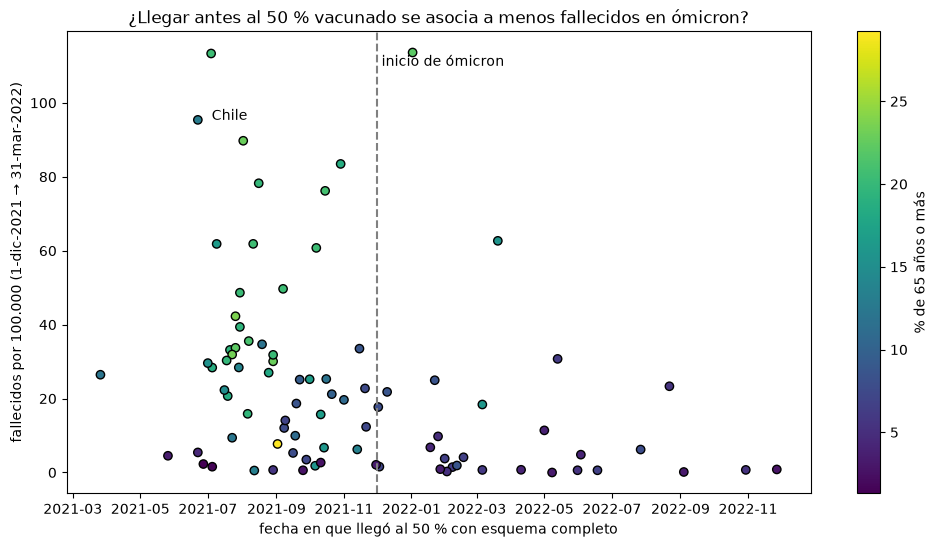

In [27]:
# Fecha de llegada al 50 % frente a fallecidos en ómicron; el color es el % de 65 años o más
fig, eje = plt.subplots(figsize=(12, 6))
puntos = eje.scatter(llegaron["fecha_50"], llegaron["fallecidos_omicron_100k"], c=llegaron["pct_65_mas"],
                     cmap="viridis", edgecolor="black")
eje.axvline(pd.Timestamp("2021-12-01"), color="gray", linestyle="--")
eje.text(pd.Timestamp("2021-12-05"), 110, "inicio de ómicron")
fila_chile = llegaron.loc["Chile"]
eje.annotate("Chile", (fila_chile["fecha_50"], fila_chile["fallecidos_omicron_100k"]), xytext=(10, 0),
             textcoords="offset points")
fig.colorbar(puntos, label="% de 65 años o más")
eje.set_xlabel("fecha en que llegó al 50 % con esquema completo")
eje.set_ylabel("fallecidos por 100.000 (1-dic-2021 → 31-mar-2022)")
eje.set_title("¿Llegar antes al 50 % vacunado se asocia a menos fallecidos en ómicron?")
plt.show()

### El factor que confunde: la edad (y el ingreso)
Los países que vacunaron primero son los **más ricos y más envejecidos** (Spearman de días hasta el 50 % con PIB: −0,74;
con % 65+: −0,48), y la edad es justamente lo que más se asocia a los fallecidos (0,77). Además, los países ricos registran
mejor sus fallecidos. Comparar a todos juntos mezcla esas diferencias.

Para compararlos de forma más justa, se separan los países en **tres grupos de edad** (tercios de `pct_65_mas`) y se
compara dentro de cada grupo. Taiwán queda fuera porque el Banco Mundial no tiene su dato.

In [28]:
con_edad = p7[p7["pct_65_mas"].notna()].copy()
con_edad["grupo_edad"] = pd.qcut(con_edad["pct_65_mas"], 3, labels=["joven", "media", "envejecida"])
rangos_edad = con_edad.groupby("grupo_edad", observed=True)["pct_65_mas"].agg(["min", "max"]).round(1)
print(rangos_edad)
por_edad = con_edad.groupby(["grupo_edad", "llego_antes"], observed=True)["fallecidos_omicron_100k"].agg(["size", "median"])
por_edad.round(1)

             min   max
grupo_edad            
joven        1.3   3.9
media        3.9  11.9
envejecida  11.9  29.2


size  median
grupo_edad llego_antes              
joven      False          45     0.6
           True            6     2.2
media      False          36     5.5
           True           15    14.1
envejecida False          14    60.0
           True           37    30.3

### Respuesta a P7
**Comparando a todos juntos, la respuesta parece "no"**: los países que llegaron antes al 50 % tuvieron **más** fallecidos
en ómicron. Es una correlación engañosa: los que vacunaron primero son países ricos y envejecidos, y la edad es lo que más
pesa en la mortalidad (Spearman 0,77 entre % 65+ y fallecidos).

**Comparando países de edad parecida, sí aparece la relación esperada donde importa:**
- En el **tercio más envejecido** (12 % a 29 % de 65+), los que llegaron al 50 % **antes** de ómicron tuvieron una mediana de
  **30,3 fallecidos por 100.000**, contra **60,0** de los que no llegaron: **la mitad**.
- En los tercios más jóvenes la relación se invierte, pero ahí los fallecidos son bajos (medianas de 0,6 a 14,1) y los
  países que vacunaron tarde son en su mayoría de ingreso bajo, con poco testeo y registro de defunciones incompleto
  (P4 y H4.3). Ahí un número bajo puede ser falta de registro, no menos muertes.

**Chile** llegó al 50 % el 22-jun-2021 y está en el tercio envejecido (13 % de 65+). Tuvo 95,4 fallecidos por 100.000,
6.º de 154, pero eso incluye la carga en bloque del 21-mar-2022. Sin ella serían ≈ 35,5, cerca de la mediana de su grupo.
(Otros países pueden tener cargas parecidas que no revisamos.)

**Correlación ≠ causalidad.** Aun dentro de un grupo de edad, los países que vacunaron antes también se diferencian en
ingreso, sistema de salud, contagios previos, testeo y momento en que llegó ómicron. Estos datos muestran una
**asociación compatible** con que vacunar antes protegió a los países más envejecidos. **No la prueban.**